In [2]:
import numpy as np
import pandas as pd
import random as rd

## 1. Probabilities of 100 variables generated randomly between 0 to 100

In [3]:
list1 = [ ]
for i in range(100):
    list1.append(rd.randint(1,10))


In [4]:
sr1 = pd.Series(list1)
sr1.value_counts()

3     13
10    12
2     12
8     11
7     10
5     10
1     10
4      9
9      7
6      6
Name: count, dtype: int64

In [5]:
sr1.unique()

array([ 4, 10,  7,  5,  3,  6,  8,  2,  9,  1])

In [6]:
sr1.nunique()

10

In [7]:
sr1.value_counts()/sr1.value_counts().sum()

3     0.13
10    0.12
2     0.12
8     0.11
7     0.10
5     0.10
1     0.10
4     0.09
9     0.07
6     0.06
Name: count, dtype: float64

## 2. Parametric Density Estimation using 1000 Sample data

In [8]:
import matplotlib.pyplot as plt
from numpy.random import normal

sample = normal(loc= 50, scale= 5, size= 1000)

# loc(mean) ~ 50
# scale(standard deviation) ~ 5
# size(no. of observations) = 1000

In [9]:
sample.mean()

np.float64(49.919453639464784)

In [10]:
sample.std()

np.float64(4.916513376538583)

(array([  4.,   5.,   6.,  22.,  33.,  55.,  75.,  92., 143., 145., 123.,
         99.,  88.,  49.,  33.,  15.,   9.,   2.,   0.,   2.]),
 array([34.21497696, 35.87617045, 37.53736393, 39.19855741, 40.8597509 ,
        42.52094438, 44.18213787, 45.84333135, 47.50452484, 49.16571832,
        50.8269118 , 52.48810529, 54.14929877, 55.81049226, 57.47168574,
        59.13287922, 60.79407271, 62.45526619, 64.11645968, 65.77765316,
        67.43884665]),
 <BarContainer object of 20 artists>)

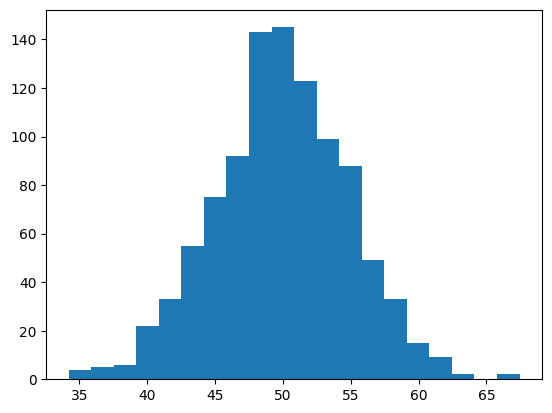

In [11]:
# plot histogram of the sample data

plt.hist(sample, bins=20)

In [12]:
#Calculate sample mean and standard deviation 

sample_mean = sample.mean()
sample_std = sample.std()

In [13]:
# fit the distribution with the above parameters

from scipy.stats import norm
dist = norm(sample_mean, sample_std)

In [14]:
# Now I'll generate 100 values between the min and max value of sample and 
# then calculate their probability density

minS = sample.min()
maxS = sample.max()

values = np.linspace(minS, maxS, 100)
values[:5]

array([34.21497696, 34.55057161, 34.88616625, 35.22176089, 35.55735553])

In [15]:
# Now calculating the probabilities using pdf function of norm
# The function takes x So using loop we pass each value from values to x, to be used in the pdf function

probabilities = [dist.pdf(values) for value in values]

In [16]:
probabilities

[array([0.00049394, 0.00061285, 0.00075685, 0.00093034, 0.00113829,
        0.00138624, 0.00168035, 0.00202739, 0.00243474, 0.00291034,
        0.00346267, 0.00410068, 0.00483366, 0.00567118, 0.00662289,
        0.00769835, 0.00890686, 0.01025719, 0.01175732, 0.0134142 ,
        0.01523343, 0.01721897, 0.01937283, 0.0216948 , 0.02418214,
        0.02682935, 0.029628  , 0.03256648, 0.03563001, 0.03880052,
        0.04205675, 0.04537434, 0.04872608, 0.05208218, 0.05541066,
        0.05867783, 0.0618488 , 0.06488809, 0.06776029, 0.07043071,
        0.07286607, 0.07503521, 0.07690976, 0.07846469, 0.07967895,
        0.08053589, 0.08102366, 0.08113546, 0.08086976, 0.08023023,
        0.07922577, 0.07787023, 0.07618209, 0.07418411, 0.07190273,
        0.06936756, 0.06661069, 0.06366606, 0.06056874, 0.05735425,
        0.0540579 , 0.05071417, 0.0473561 , 0.04401483, 0.04071915,
        0.03749513, 0.03436589, 0.03135139, 0.02846836, 0.02573029,
        0.02314747, 0.02072711, 0.01847355, 0.01

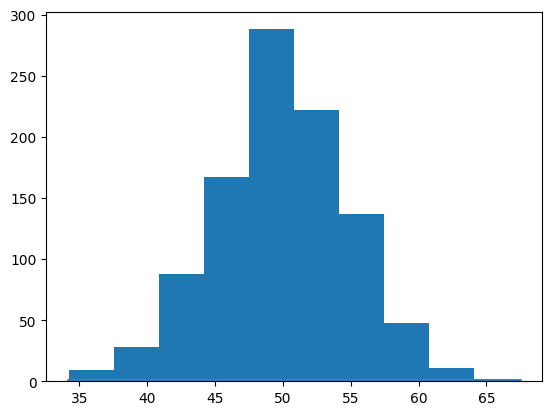

In [25]:
# Now plotting the a hist plot between values and their probabilities, also plotting a pdf

plt.hist(sample, bins= 10)
plt.plot(values, probabilities)

In [18]:
import seaborn as sb

<Axes: ylabel='Count'>

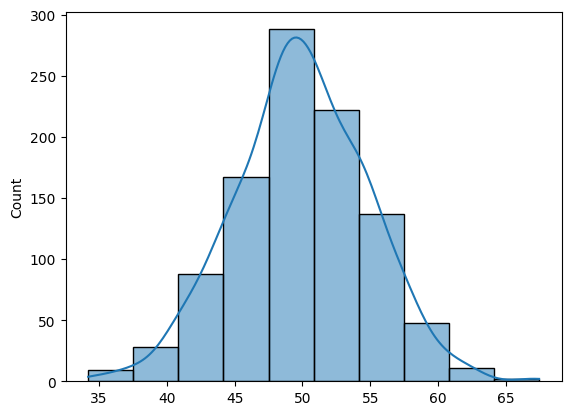

In [19]:
sb.histplot(data= sample, bins= 10, kde= True) 

In [20]:
import plotly.express as px

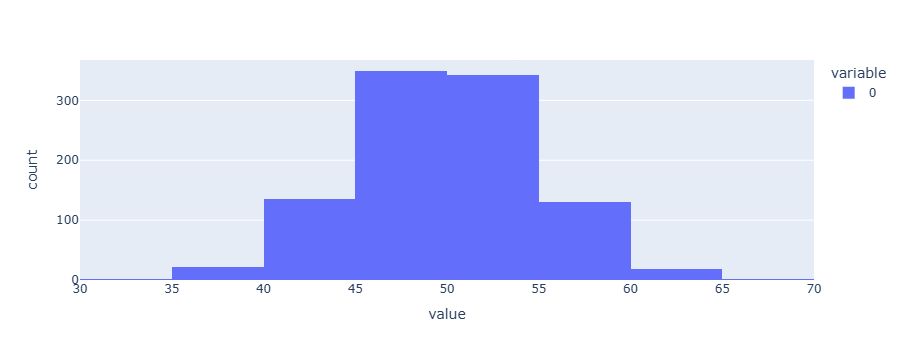

In [21]:
fig = px.histogram(sample, nbins= 10)
fig.show()

## KDE

In [42]:
sample1 = normal(loc= 20, scale= 5, size= 300)
sample2 = normal(loc= 40, scale= 5, size= 700)

# hstack -> horizontal stack it will merge sample1 and sample2 side by side
sample3 = np.hstack((sample1, sample2))

In [69]:
# Imports the KernelDensity class from scikit-learn, used for KDE modeling.
from sklearn.neighbors import KernelDensity

# Creates a KDE model.
# bandwidth=3 → Controls smoothness of the curve (higher = smoother).
# kernel="gaussian" → Uses Gaussian kernel for density estimation.
model = KernelDensity(bandwidth= 0.1, kernel= "gaussian")

#convert data to 2D array(as ML widely understand 2D array)
sample1 = sample1.reshape(len(sample1), 1)

# Fits the KDE model on sample1.
# 👉 Learns the probability distribution of those 300 values.
model.fit(sample1)

,bandwidth,0.1
,algorithm,'auto'
,kernel,'gaussian'
,metric,'euclidean'
,atol,0
,rtol,0
,breadth_first,True
,leaf_size,40
,metric_params,None


In [70]:
values1 = np.linspace(sample3.min(), sample3.max(), 100)
values1 = values1.reshape(len(values1), 1)

In [71]:
# Returns the log probability density at each point in values1.
probabilities1 = model.score_samples(values1)

# to cancel the log we use exponent function
probabilities2 = np.exp(probabilities1)

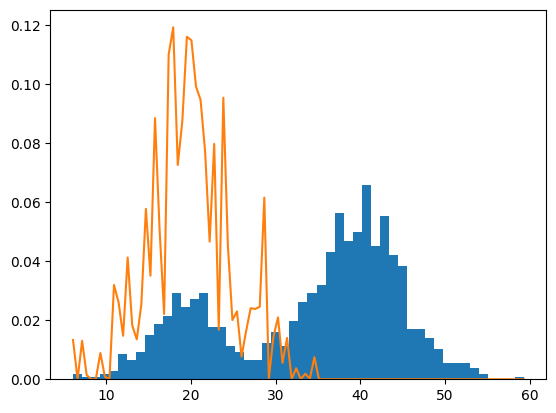

In [72]:
plt.hist(sample3, bins=50, density=True)
plt.plot(values1[:], probabilities2)
plt.show()